# Задание 2.2

Решите уравнение и изобразите множество решений на комплексной плоскости:

$$
z^8 = 1 + i.
$$

## Теория

Уравнение $z^n = w$ при $w\neq 0$ имеет ровно $n$ различных корней. Если $w=\rho e^{i\varphi}$, то по формуле Муавра

$$
z_k=\sqrt[n]{\rho}\,\exp\!\left(i\,\frac{\varphi+2\pi k}{n}\right),\qquad k=0,1,\dots,n-1 .
$$

Все корни лежат на окружности радиуса $\sqrt[n]{\rho}$ с центром в нуле и являются вершинами правильного $n$-угольника.

**В нашей задаче** $w=1+i=\sqrt2\,e^{i\pi/4}$, $n=8$:

$$
z_k=\sqrt[16]{2}\,\exp\!\left(i\left(\frac{\pi}{32}+\frac{\pi k}{4}\right)\right),\qquad k=0,\dots,7 .
$$

Решения — вершины правильного восьмиугольника, вписанного в окружность радиуса $\sqrt[16]{2}\approx1{,}0443$, повёрнутого на угол $\pi/32$.

|z_k| = 2^(1/16) = 1.044274
z_0 = +1.039245 +0.102357i,   arg z_0 = π/32 + 0·π/4 = 0.098175
z_1 = +0.662480 +0.807235i,   arg z_1 = π/32 + 1·π/4 = 0.883573
z_2 = -0.102357 +1.039245i,   arg z_2 = π/32 + 2·π/4 = 1.668971
z_3 = -0.807235 +0.662480i,   arg z_3 = π/32 + 3·π/4 = 2.454369
z_4 = -1.039245 -0.102357i,   arg z_4 = π/32 + 4·π/4 = 3.239767
z_5 = -0.662480 -0.807235i,   arg z_5 = π/32 + 5·π/4 = 4.025166
z_6 = +0.102357 -1.039245i,   arg z_6 = π/32 + 6·π/4 = 4.810564
z_7 = +0.807235 -0.662480i,   arg z_7 = π/32 + 7·π/4 = 5.595962

max |z_k^8 - (1+i)| = 6.915539919559704e-15


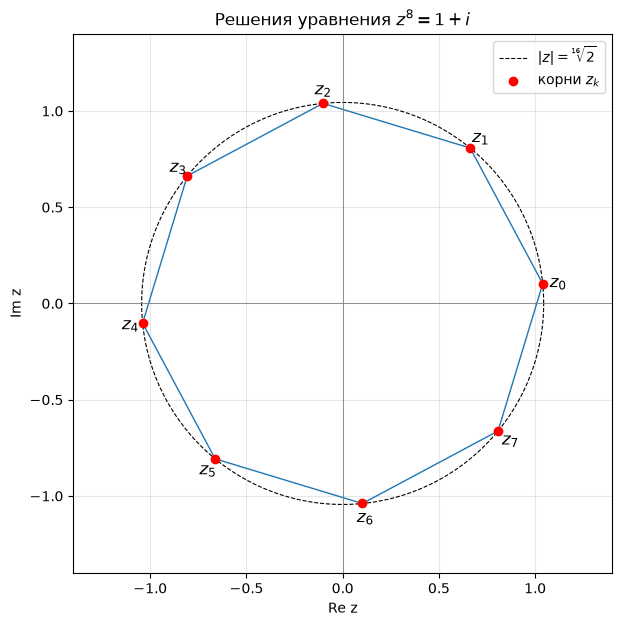

In [1]:
import numpy as np
import matplotlib.pyplot as plt

w = 1 + 1j      # правая часть уравнения
n = 8           # степень

# Модуль и аргумент правой части: w = rho·e^{i·phi}
rho, phi = abs(w), np.angle(w)

# Формула корней n-й степени: z_k = rho^{1/n}·exp(i(phi + 2πk)/n), k = 0..n-1
k = np.arange(n)
r = rho**(1/n)
args = (phi + 2*np.pi*k)/n
z = r*np.exp(1j*args)

print(f"|z_k| = 2^(1/16) = {r:.6f}")
for kk, zk, a in zip(k, z, args):
    print(f"z_{kk} = {zk.real:+.6f} {zk.imag:+.6f}i,   arg z_{kk} = π/32 + {kk}·π/4 = {a:.6f}")

# Проверка: подставляем корни в уравнение
print("\nmax |z_k^8 - (1+i)| =", np.max(np.abs(z**n - w)))

# Рисунок: корни — вершины правильного 8-угольника на окружности радиуса 2^(1/16)
fig, ax = plt.subplots(figsize=(7, 7))
t = np.linspace(0, 2*np.pi, 400)
ax.plot(r*np.cos(t), r*np.sin(t), 'k--', lw=0.8, label=r"$|z|=\sqrt[16]{2}$")
ax.plot(np.append(z.real, z.real[0]), np.append(z.imag, z.imag[0]), color='tab:blue', lw=1)
ax.scatter(z.real, z.imag, color='red', zorder=3, label="корни $z_k$")
for kk, zk in zip(k, z):
    ax.annotate(f"$z_{kk}$", (zk.real, zk.imag), textcoords="offset points",
                xytext=(10*np.cos(args[kk]) - 5, 10*np.sin(args[kk]) - 4), fontsize=12)

ax.axhline(0, color='gray', lw=0.6)
ax.axvline(0, color='gray', lw=0.6)
ax.set_aspect('equal')
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.grid(alpha=0.3)
ax.set_xlabel("Re z")
ax.set_ylabel("Im z")
ax.set_title(r"Решения уравнения $z^8 = 1 + i$")
ax.legend(loc="upper right")
plt.show()